In [3]:
"""День 2: таргет K, модель лимитов, Парето динамического K.

Загружает артефакты Дня 1 из data/processed/.
Не переобучает модели — они уже обучены в day1_baseline.ipynb.
"""

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cascade
import evaluation as ev

print("=" * 60)
print("Загрузка артефактов Дня 1")
print("=" * 60)

# 1. Сплиты
df_a = pd.read_pickle(config.DATA_PROCESSED / "df_a.pkl")
df_b = pd.read_pickle(config.DATA_PROCESSED / "df_b.pkl")
df_c = pd.read_pickle(config.DATA_PROCESSED / "df_c.pkl")

# 2. Метаданные (признаки, сид, сетка K)
meta = pd.read_pickle(config.DATA_PROCESSED / "features_meta.pkl")
cheap_features = meta["cheap_features"]
all_features = meta["all_features"]

# 3. Модели
cheap_ranker, expensive_ranker = cascade.load_models()

# 4. Fixed-K таблица (для сравнения)
fixed_df = pd.read_csv(config.REPORTS / "fixed_k_results.csv")

# --- Проверки ---
print(f"Сплиты: A={df_a.shape}, B={df_b.shape}, C={df_c.shape}")
print(f"Запросы: A={meta['n_queries_a']}, B={meta['n_queries_b']}, C={meta['n_queries_c']}")
print(f"Признаки: cheap={len(cheap_features)}, all={len(all_features)}")

n_trees_cb = expensive_ranker.tree_count_
n_trees_lgb = cheap_ranker.num_trees()   # у Booster — num_trees(), не booster_.num_trees()
print(f"Модели: CatBoost={n_trees_cb} деревьев, LightGBM={n_trees_lgb} деревьев")

assert n_trees_cb >= 200, f"CatBoost: {n_trees_cb} — переобучите в day1"
assert n_trees_lgb >= 50, f"LightGBM: {n_trees_lgb} — переобучите в day1"
assert len(cheap_features) == 30
assert len(all_features) == 136
assert len(fixed_df) == len(config.K_GRID)

print("\n" + "=" * 60)
print("Всё готово для Дня 2")
print("=" * 60)
print("\nFixed-K baseline:")
print(fixed_df.to_string(index=False))

Загрузка артефактов Дня 1
Сплиты: A=(11778, 138), B=(4279, 138), C=(3882, 138)
Запросы: A=103, B=34, C=35
Признаки: cheap=30, all=136
Модели: CatBoost=300 деревьев, LightGBM=80 деревьев

Всё готово для Дня 2

Fixed-K baseline:
  K  mean_ndcg@10   mean_cost
  5      0.258344  160.057143
 10      0.373615  208.628571
 20      0.404993  305.200000
 30      0.445191  399.485714
 50      0.465391  584.628571
 75      0.467737  795.485714
100      0.470990  968.914286
150      0.471832 1143.200000
200      0.472024 1188.342857
230      0.472024 1205.485714


In [4]:
def compute_targets(df, cheap_model, expensive_model,
                    cheap_features, all_features,
                    k_grid, epsilons):
    """Таргет K: минимальный K, при котором ndcg_full - ndcg_k <= eps.

    Оптимизация: дорогая модель прогоняется один раз на всех документах,
    скоры для top-K берутся из этого прогона.
    """
    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)
        true_labels = group["target"].values

        # Дешёвая — один прогон
        X_cheap = group[cheap_features].values.astype("float32")
        cheap_scores = cheap_model.predict(X_cheap)
        order_cheap = np.argsort(cheap_scores)[::-1]

        # Дорогая — один прогон на всех (это K=all)
        X_full = group[all_features].values.astype("float32")
        expensive_full = expensive_model.predict(X_full)

        ndcg_full = ev.ndcg_at_k(true_labels, expensive_full, k=10)

        row = {"query_id": qid, "n_docs": n_docs, "ndcg_full": ndcg_full}

        for k in k_grid:
            k_eff = min(k, n_docs)
            top_k_idx = order_cheap[:k_eff]

            aligned = np.full(n_docs, -np.inf)
            aligned[top_k_idx] = expensive_full[top_k_idx]

            row[f"ndcg_at_{k}"] = ev.ndcg_at_k(true_labels, aligned, k=10)

        for eps in epsilons:
            target = k_grid[-1]
            for k in k_grid:
                if row["ndcg_full"] - row[f"ndcg_at_{k}"] <= eps:
                    target = k
                    break
            row[f"target_eps_{eps}"] = target

        rows.append(row)

    return pd.DataFrame(rows)


print("compute_targets определена")

compute_targets определена


In [5]:
targets_b = compute_targets(
    df_b, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    k_grid=list(config.K_GRID),
    epsilons=config.EPSILONS,
)

print(f"targets_b: {targets_b.shape}")
print(targets_b.head(3).to_string())

targets_b: (34, 16)
   query_id  n_docs  ndcg_full  ndcg_at_5  ndcg_at_10  ndcg_at_20  ndcg_at_30  ndcg_at_50  ndcg_at_75  ndcg_at_100  ndcg_at_150  ndcg_at_200  ndcg_at_230  target_eps_0.0  target_eps_0.01  target_eps_0.02
0        46     120   0.526265   0.527368    0.595985    0.543291    0.520059    0.533650    0.526265     0.526265     0.526265     0.526265     0.526265               5                5                5
1        76      45   0.667706   0.479635    0.493610    0.521508    0.667706    0.667706    0.667706     0.667706     0.667706     0.667706     0.667706              30               30               30
2        88     168   0.305945   0.223276    0.292543    0.327817    0.442513    0.354574    0.326482     0.305945     0.305945     0.305945     0.305945              20               20               10


In [9]:
def build_limit_features(df, cheap_model, cheap_features, all_features):
    """Признаки для модели лимитов. Только то, что известно ПОСЛЕ дешёвой
    стадии и ДО вызова дорогой.

    Возвращает DataFrame: query_id + признаки. Одна строка на запрос.
    """
    # Топ-10 признаков по важности дешёвой модели (а не первые 10)
    importance = pd.DataFrame({
        "feature": cheap_features,
        "gain": cheap_model.feature_importance(importance_type="gain"),
    }).sort_values("gain", ascending=False)
    top_feats = importance.head(10)["feature"].tolist()

    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)

        X_cheap = group[cheap_features].values.astype("float32")
        scores = cheap_model.predict(X_cheap)
        scores_sorted = np.sort(scores)[::-1]

        # --- 1. О запросе ---
        row = {
            "query_id": qid,
            "n_docs": n_docs,
            "log_n_docs": float(np.log1p(n_docs)),
        }

        # --- 2. О скорах дешёвой модели ---
        row["score_max"] = float(scores.max())
        row["score_min"] = float(scores.min())
        row["score_std"] = float(scores.std())
        row["score_mean"] = float(scores.mean())

        # Разрывы между 1-м и другими документами
        row["gap_1_2"] = float(scores_sorted[0] - scores_sorted[1]) if n_docs >= 2 else 0.0
        for k in [5, 10, 20]:
            row[f"gap_1_{k}"] = (
                float(scores_sorted[0] - scores_sorted[k - 1])
                if n_docs >= k else 0.0
            )

        # Энтропия нормированных скоров (softmax с T=1)
        exp_s = np.exp(scores - scores.max())
        p = exp_s / exp_s.sum()
        row["score_entropy"] = float(-np.sum(p * np.log(p + 1e-12)))

        # --- 3. Агрегаты top-10 важных признаков по top-10 документов ---
        top_10_idx = np.argsort(scores)[::-1][:min(10, n_docs)]
        for feat in top_feats:
            vals = group.iloc[top_10_idx][feat].values.astype("float32")
            row[f"top10_f{feat}_mean"] = float(vals.mean())
            row[f"top10_f{feat}_std"] = float(vals.std())
            row[f"top10_f{feat}_max"] = float(vals.max())

        rows.append(row)

    return pd.DataFrame(rows)


print("build_limit_features определена")

build_limit_features определена


In [10]:
features_b = build_limit_features(df_b, cheap_ranker, cheap_features, all_features)
features_c = build_limit_features(df_c, cheap_ranker, cheap_features, all_features)

print("=" * 60)
print("Признаки для модели лимитов")
print("=" * 60)
print(f"features_b: {features_b.shape}  ({features_b['query_id'].nunique()} запросов)")
print(f"features_c: {features_c.shape}  ({features_c['query_id'].nunique()} запросов)")
print(f"Признаков (без query_id): {features_b.shape[1] - 1}")

# --- Проверки ---
assert features_b.shape[1] == features_c.shape[1], \
    f"Разное число колонок: B={features_b.shape[1]}, C={features_c.shape[1]}"
assert list(features_b.columns) == list(features_c.columns), \
    "Порядок/имена колонок не совпадают между B и C"
assert features_b["query_id"].nunique() == df_b["query_id"].nunique(), \
    "Не все запросы B попали в признаки"
assert features_c["query_id"].nunique() == df_c["query_id"].nunique(), \
    "Не все запросы C попали в признаки"

# Проверка на NaN и inf
for name, feat in [("B", features_b), ("C", features_c)]:
    X = feat.drop(columns=["query_id"]).values
    n_nan = np.isnan(X).sum()
    n_inf = np.isinf(X).sum()
    assert n_nan == 0, f"{name}: {n_nan} NaN в признаках"
    assert n_inf == 0, f"{name}: {n_inf} inf в признаках"

print("\nПроверки пройдены: структура B и C одинаковая, NaN/inf нет")
print(f"\nКолонки (первые 10): {list(features_b.columns[:10])}")
print(f"Колонки (последние 5): {list(features_b.columns[-5:])}")

Признаки для модели лимитов
features_b: (34, 42)  (34 запросов)
features_c: (35, 42)  (35 запросов)
Признаков (без query_id): 41

Проверки пройдены: структура B и C одинаковая, NaN/inf нет

Колонки (первые 10): ['query_id', 'n_docs', 'log_n_docs', 'score_max', 'score_min', 'score_std', 'score_mean', 'gap_1_2', 'gap_1_5', 'gap_1_10']
Колонки (последние 5): ['top10_f22_std', 'top10_f22_max', 'top10_f31_mean', 'top10_f31_std', 'top10_f31_max']


In [15]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split


def train_limit_model(features_df, targets_df, target_col,
                      alpha=0.7, val_frac=0.2, n_estimators=300,
                      seed=None, verbose=False):
    """LightGBM quantile regression на log(K+1).

    Параметры:
    - alpha: целевой квантиль. 0.5 — медиана (без запаса вверх),
             0.7 — умеренный запас, 0.9 — сильный запас вверх.
    - val_frac: доля запросов на валидацию (для early stopping).
    - n_estimators: верхняя граница числа деревьев; early stopping
                    может остановить раньше.

    Возвращает (model, feature_cols).
    """
    df = features_df.merge(targets_df[["query_id", target_col]], on="query_id")
    assert len(df) == len(features_df), \
        f"После merge стало {len(df)} строк вместо {len(features_df)} — не все query_id сматчились"

    feature_cols = [c for c in df.columns
                    if c != "query_id" and not c.startswith("target")]

    # Сплит по query_id (по строкам здесь = по запросам, т.к. одна строка на запрос)
    qids = df["query_id"].values
    train_q, val_q = train_test_split(
        qids, test_size=val_frac,
        random_state=seed if seed is not None else config.SEED,
    )
    train_df = df[df["query_id"].isin(train_q)]
    val_df   = df[df["query_id"].isin(val_q)]

    X_train = train_df[feature_cols].values.astype("float32")
    y_train = np.log1p(train_df[target_col].values.astype("float32"))
    X_val   = val_df[feature_cols].values.astype("float32")
    y_val   = np.log1p(val_df[target_col].values.astype("float32"))

    model = lgb.LGBMRegressor(
        objective="quantile",
        alpha=alpha,
        n_estimators=n_estimators,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=5,
        min_child_samples=3,
        random_state=seed if seed is not None else config.SEED,
        verbose=-1,
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="quantile",
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    if verbose:
        print(f"    обучено деревьев: {model.best_iteration_ or n_estimators}")

    return model, feature_cols


def predict_k(model, features_df, feature_cols, k_grid):
    """Предсказать K, округлить вверх до ближайшего значения из сетки.

    Логика округления: если модель предсказала 23.4, а сетка = {5,10,20,30,...},
    берём 30 (ceil), а не 20. Причина — асимметрия: переоценить K дешевле,
    чем недооценить.
    """
    X = features_df[feature_cols].values.astype("float32")
    preds_log = model.predict(X)
    preds_k = np.expm1(preds_log)  # обратно из log(K+1)

    k_arr = np.array(sorted(k_grid), dtype=np.float64)
    # searchsorted с side="left" находит первый индекс, где k_arr[idx] >= preds_k
    idx = np.searchsorted(k_arr, preds_k, side="left")
    idx = np.clip(idx, 0, len(k_arr) - 1)   # если preds_k > max(k_grid) — берём max
    k_pred = k_arr[idx].astype(int)

    return pd.DataFrame({
        "query_id": features_df["query_id"].values,
        "predicted_k_continuous": preds_k,
        "predicted_k": k_pred,
    })


print("train_limit_model и predict_k определены")

train_limit_model и predict_k определены


In [16]:
def apply_dynamic_k(df, cheap_model, expensive_model,
                    cheap_features, all_features, predicted_k_df):
    """Каскад с предсказанным K для каждого запроса.

    Возвращает DataFrame: query_id, k_pred, ndcg@10, cost.
    Одна строка на запрос.
    """
    k_map = dict(zip(predicted_k_df["query_id"], predicted_k_df["predicted_k"]))

    rows = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)
        n_docs = len(group)

        # Если для запроса нет предсказания — fallback на max K (безопасно)
        k = k_map.get(qid, max(config.K_GRID))
        k_eff = min(k, n_docs)

        # Дешёвая — один прогон на всех документах
        X_cheap = group[cheap_features].values.astype("float32")
        cheap_scores = cheap_model.predict(X_cheap)
        top_k_idx = np.argsort(cheap_scores)[::-1][:k_eff]

        # Дорогая — один прогон на всех документах (используем скоры только для top-K)
        X_full = group[all_features].values.astype("float32")
        expensive_full = expensive_model.predict(X_full)

        # Выравниваем скоры: top-K от дорогой, остальные — -inf
        aligned = np.full(n_docs, -np.inf)
        aligned[top_k_idx] = expensive_full[top_k_idx]

        ndcg = ev.ndcg_at_k(group["target"].values, aligned, k=10)
        cost = ev.cascade_cost_per_query(k, n_docs)

        rows.append({
            "query_id": qid,
            "k_pred": k,
            "ndcg@10": ndcg,
            "cost": cost,
        })

    return pd.DataFrame(rows)


print("apply_dynamic_k определена")

apply_dynamic_k определена


In [17]:
# Считаем таргет на C ОДИН раз для всех eps — это для честной проверки under.
# compute_targets на 35 запросах × 7 K — секунды. Без этого мы бы считали
# её 15 раз (по разу на каждую конфигурацию), что в 15 раз дольше.
print("Считаем таргеты на C для проверки under...")
targets_c = compute_targets(
    df_c, cheap_ranker, expensive_ranker,
    cheap_features, all_features,
    k_grid=list(config.K_GRID),
    epsilons=config.EPSILONS,
)
print(f"targets_c: {targets_c.shape}\n")

# Сетка конфигураций
ALPHAS = [0.5, 0.6, 0.7, 0.8, 0.9]

print("=" * 95)
print(f"{'eps':>5} {'alpha':>6} {'ndcg':>8} {'cost':>8} {'under':>7} {'trees':>6} {'k_dist':>45}")
print("-" * 95)

sweep_results = []

for eps in config.EPSILONS:
    target_col = f"target_eps_{eps}"

    for alpha in ALPHAS:
        model, feat_cols = train_limit_model(
            features_b, targets_b,
            target_col=target_col,
            alpha=alpha,
        )

        # Предсказание и прогон на C
        pred_c = predict_k(model, features_c, feat_cols, config.K_GRID)
        dyn = apply_dynamic_k(
            df_c, cheap_ranker, expensive_ranker,
            cheap_features, all_features, pred_c,
        )

        # under — доля запросов, где модель предсказала меньше таргета на C
        merged = dyn.merge(targets_c[["query_id", target_col]], on="query_id")
        under = (merged["k_pred"] < merged[target_col]).mean()

        k_dist = dict(pred_c["predicted_k"].value_counts().sort_index())
        n_trees = model.best_iteration_ or model.n_estimators_

        sweep_results.append({
            "eps": eps,
            "alpha": alpha,
            "ndcg": float(dyn["ndcg@10"].mean()),
            "cost": float(dyn["cost"].mean()),
            "under": float(under),
            "n_trees": n_trees,
            "k_dist": k_dist,
            "model": model,           # сохраняем — понадобится для лучшей конфигурации
            "feature_cols": feat_cols,
            "pred_c": pred_c,
            "dyn": dyn,
        })

        k_str = ",".join(f"{k}:{v}" for k, v in k_dist.items())
        print(f"{eps:>5} {alpha:>6} {dyn['ndcg@10'].mean():>8.4f} "
              f"{dyn['cost'].mean():>8.1f} {under:>6.0%} {n_trees:>6} {k_str:>45}")

sweep_df = pd.DataFrame(sweep_results)
print("\n" + "=" * 95)
print(f"Всего конфигураций: {len(sweep_df)}")

Считаем таргеты на C для проверки under...
targets_c: (35, 16)

  eps  alpha     ndcg     cost   under  trees                                        k_dist
-----------------------------------------------------------------------------------------------


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  0.0    0.5   0.4165    328.1    51%      1                                    20:27,30:8


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  0.0    0.6   0.4396    390.9    43%     12                              20:15,30:15,50:5


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (21 outputs left out)

/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 0.02    0.8   0.4514    462.3    23%     26                    20:5,30:22,50:5,75:2,100:1


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 0.02    0.9   0.4677    795.5     9%      1                                         75:35

Всего конфигураций: 15


In [18]:
from scipy.interpolate import interp1d

# Интерполятор по fixed-K кривой: для любой стоимости даст NDCG, который
# дал бы лучший fixed-K за те же деньги
fixed_interp = interp1d(
    fixed_df["mean_cost"], fixed_df["mean_ndcg@10"],
    kind="linear", bounds_error=False, fill_value="extrapolate",
)

# Фильтр: не слишком агрессивные и не вырожденные
candidates = sweep_df[
    (sweep_df["under"] <= 0.25) &
    (sweep_df["k_dist"].apply(len) >= 2)
].copy()

if len(candidates) == 0:
    print("⚠️  Ни одна конфигурация не прошла фильтр under<=25% и k_dist>=2.")
    print("    Ослабляю фильтр: under <= 0.40, k_dist >= 2.")
    candidates = sweep_df[
        (sweep_df["under"] <= 0.40) &
        (sweep_df["k_dist"].apply(len) >= 2)
    ].copy()

# Считаем выигрыш над fixed-K при той же стоимости
candidates["fixed_ndcg_at_same_cost"] = fixed_interp(candidates["cost"].values)
candidates["pareto_gain"] = candidates["ndcg"] - candidates["fixed_ndcg_at_same_cost"]

# Сортируем: сначала по pareto_gain (убывание), потом по under (возрастание)
candidates = candidates.sort_values(
    ["pareto_gain", "under"], ascending=[False, True]
).reset_index(drop=True)

print("Кандидаты (после фильтра under<=25%, k_dist>=2):")
print(candidates[["eps", "alpha", "ndcg", "cost", "under",
                  "fixed_ndcg_at_same_cost", "pareto_gain"]].to_string(index=False))

best_row = candidates.iloc[0]
best_eps = float(best_row["eps"])
best_alpha = float(best_row["alpha"])

print("\n" + "=" * 70)
print("Выбрана финальная конфигурация")
print("=" * 70)
print(f"  eps   = {best_eps}")
print(f"  alpha = {best_alpha}")
print(f"  NDCG@10 = {best_row['ndcg']:.4f}")
print(f"  cost    = {best_row['cost']:.1f}")
print(f"  under   = {best_row['under']:.0%}")
print(f"  k_dist  = {dict(best_row['k_dist'])}")
print(f"\n  Fixed-K при той же cost: {best_row['fixed_ndcg_at_same_cost']:.4f}")
print(f"  Pareto gain:             {best_row['pareto_gain']:+.4f}")

# Сравнение с фиксированным K=50 (как «разумная отправная точка»)
fixed_k50 = fixed_df[fixed_df["K"] == 50].iloc[0]
cost_saving = (fixed_k50["mean_cost"] - best_row["cost"]) / fixed_k50["mean_cost"]
ndcg_delta  = best_row["ndcg"] - fixed_k50["mean_ndcg@10"]
print(f"\n  Сравнение с Fixed K=50 (cost={fixed_k50['mean_cost']:.0f}, "
      f"NDCG={fixed_k50['mean_ndcg@10']:.4f}):")
print(f"    Экономия cost: {-cost_saving:+.1%}")
print(f"    Δ NDCG:        {ndcg_delta:+.4f}")

Кандидаты (после фильтра under<=25%, k_dist>=2):
 eps  alpha     ndcg       cost    under  fixed_ndcg_at_same_cost  pareto_gain
0.01    0.8 0.456139 473.771429 0.228571                 0.453296     0.002843
0.02    0.8 0.451433 462.342857 0.228571                 0.452049    -0.000616

Выбрана финальная конфигурация
  eps   = 0.01
  alpha = 0.8
  NDCG@10 = 0.4561
  cost    = 473.8
  under   = 23%
  k_dist  = {30: np.int64(27), 50: np.int64(5), 75: np.int64(2), 100: np.int64(1)}

  Fixed-K при той же cost: 0.4533
  Pareto gain:             +0.0028

  Сравнение с Fixed K=50 (cost=585, NDCG=0.4654):
    Экономия cost: -19.0%
    Δ NDCG:        -0.0093


In [19]:
from scipy.interpolate import interp1d

# Интерполятор по fixed-K кривой: для любой стоимости даст NDCG, который
# дал бы лучший fixed-K за те же деньги
fixed_interp = interp1d(
    fixed_df["mean_cost"], fixed_df["mean_ndcg@10"],
    kind="linear", bounds_error=False, fill_value="extrapolate",
)

# Фильтр: не слишком агрессивные и не вырожденные
candidates = sweep_df[
    (sweep_df["under"] <= 0.25) &
    (sweep_df["k_dist"].apply(len) >= 2)
].copy()

if len(candidates) == 0:
    print("⚠️  Ни одна конфигурация не прошла фильтр under<=25% и k_dist>=2.")
    print("    Ослабляю фильтр: under <= 0.40, k_dist >= 2.")
    candidates = sweep_df[
        (sweep_df["under"] <= 0.40) &
        (sweep_df["k_dist"].apply(len) >= 2)
    ].copy()

# Считаем выигрыш над fixed-K при той же стоимости
candidates["fixed_ndcg_at_same_cost"] = fixed_interp(candidates["cost"].values)
candidates["pareto_gain"] = candidates["ndcg"] - candidates["fixed_ndcg_at_same_cost"]

# Сортируем: сначала по pareto_gain (убывание), потом по under (возрастание)
candidates = candidates.sort_values(
    ["pareto_gain", "under"], ascending=[False, True]
).reset_index(drop=True)

print("Кандидаты (после фильтра under<=25%, k_dist>=2):")
print(candidates[["eps", "alpha", "ndcg", "cost", "under",
                  "fixed_ndcg_at_same_cost", "pareto_gain"]].to_string(index=False))

best_row = candidates.iloc[0]
best_eps = float(best_row["eps"])
best_alpha = float(best_row["alpha"])

print("\n" + "=" * 70)
print("Выбрана финальная конфигурация")
print("=" * 70)
print(f"  eps   = {best_eps}")
print(f"  alpha = {best_alpha}")
print(f"  NDCG@10 = {best_row['ndcg']:.4f}")
print(f"  cost    = {best_row['cost']:.1f}")
print(f"  under   = {best_row['under']:.0%}")
print(f"  k_dist  = {dict(best_row['k_dist'])}")
print(f"\n  Fixed-K при той же cost: {best_row['fixed_ndcg_at_same_cost']:.4f}")
print(f"  Pareto gain:             {best_row['pareto_gain']:+.4f}")

# Сравнение с фиксированным K=50 (как «разумная отправная точка»)
fixed_k50 = fixed_df[fixed_df["K"] == 50].iloc[0]
cost_saving = (fixed_k50["mean_cost"] - best_row["cost"]) / fixed_k50["mean_cost"]
ndcg_delta  = best_row["ndcg"] - fixed_k50["mean_ndcg@10"]
print(f"\n  Сравнение с Fixed K=50 (cost={fixed_k50['mean_cost']:.0f}, "
      f"NDCG={fixed_k50['mean_ndcg@10']:.4f}):")
print(f"    Экономия cost: {-cost_saving:+.1%}")
print(f"    Δ NDCG:        {ndcg_delta:+.4f}")

Кандидаты (после фильтра under<=25%, k_dist>=2):
 eps  alpha     ndcg       cost    under  fixed_ndcg_at_same_cost  pareto_gain
0.01    0.8 0.456139 473.771429 0.228571                 0.453296     0.002843
0.02    0.8 0.451433 462.342857 0.228571                 0.452049    -0.000616

Выбрана финальная конфигурация
  eps   = 0.01
  alpha = 0.8
  NDCG@10 = 0.4561
  cost    = 473.8
  under   = 23%
  k_dist  = {30: np.int64(27), 50: np.int64(5), 75: np.int64(2), 100: np.int64(1)}

  Fixed-K при той же cost: 0.4533
  Pareto gain:             +0.0028

  Сравнение с Fixed K=50 (cost=585, NDCG=0.4654):
    Экономия cost: -19.0%
    Δ NDCG:        -0.0093


In [22]:
print("=" * 70)
print(f"Финальная модель лимитов: eps={best_eps}, alpha={best_alpha}")
print("=" * 70)

target_col_final = f"target_eps_{best_eps}"

# Обучаем финальную модель на B
limit_model_final, limit_feature_cols = train_limit_model(
    features_b, targets_b,
    target_col=target_col_final,
    alpha=best_alpha,
)

print(f"Обучено деревьев: {limit_model_final.best_iteration_ or limit_model_final.n_estimators_}")
print(f"Признаков: {len(limit_feature_cols)}")

# Предсказания на B (sanity-check) и на C (для Дня 3)
predicted_k_b = predict_k(limit_model_final, features_b, limit_feature_cols, config.K_GRID)
predicted_k_c = predict_k(limit_model_final, features_c, limit_feature_cols, config.K_GRID)

print("\nПредсказания на B (sanity-check):")
print(predicted_k_b["predicted_k"].value_counts().sort_index().to_string())

print("\nПредсказания на C (пойдут в День 3):")
print(predicted_k_c["predicted_k"].value_counts().sort_index().to_string())

# --- Проверки ---
assert predicted_k_b["predicted_k"].isin(config.K_GRID).all(), \
    "На B есть K вне сетки"
assert predicted_k_c["predicted_k"].isin(config.K_GRID).all(), \
    "На C есть K вне сетки"
assert len(predicted_k_c) == df_c["query_id"].nunique(), \
    f"predicted_k_c: {len(predicted_k_c)} строк, а в C {df_c['query_id'].nunique()} запросов"

# k_dist должен совпасть с тем, что было в sweep для этой конфигурации
best_k_dist_from_sweep = best_row["k_dist"]
best_k_dist_final = dict(predicted_k_c["predicted_k"].value_counts().sort_index())
assert best_k_dist_final == best_k_dist_from_sweep, \
    f"k_dist не совпадает со sweep: {best_k_dist_final} != {best_k_dist_from_sweep}"

print("\nВсе проверки пройдены: финальная модель воспроизводит результат sweep")

Финальная модель лимитов: eps=0.01, alpha=0.8
Обучено деревьев: 17
Признаков: 41

Предсказания на B (sanity-check):
predicted_k
30     23
50      5
75      3
100     3

Предсказания на C (пойдут в День 3):
predicted_k
30     27
50      5
75      2
100     1

Все проверки пройдены: финальная модель воспроизводит результат sweep


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


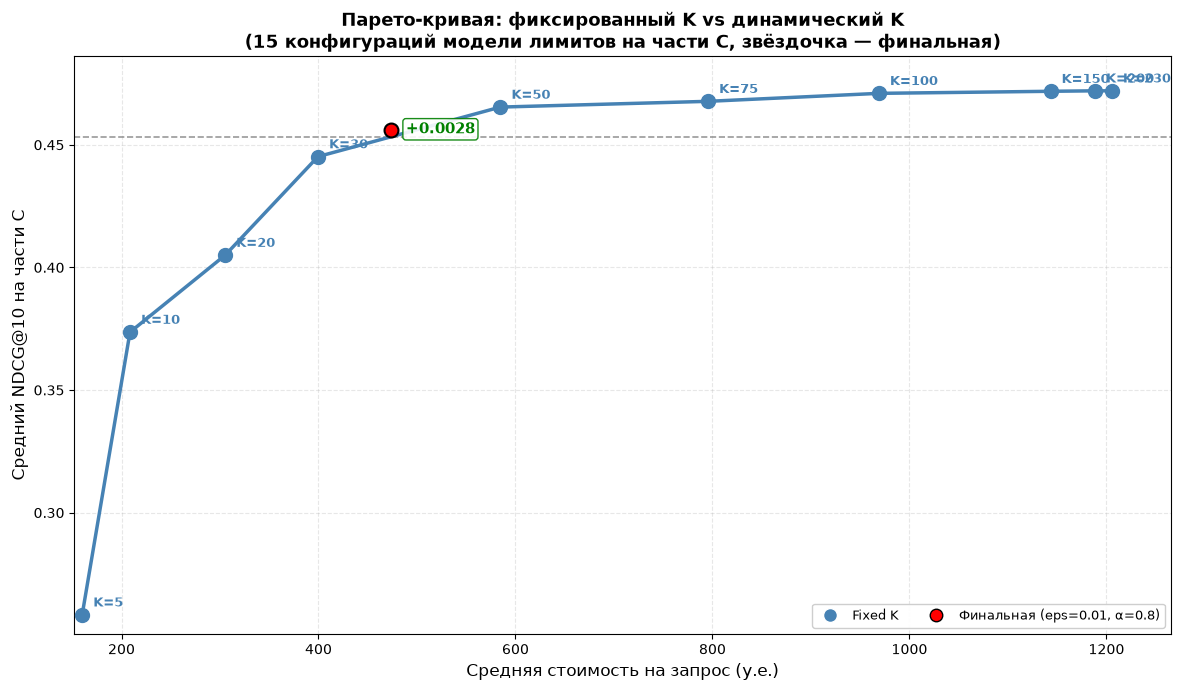

Сохранено: /home/piterburzhec/Work-Edu/ranking-project/figures/pareto_dynamic_vs_fixed.png


In [29]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 7))

# --- 1. Fixed-K кривая ---
ax.plot(
    fixed_df["mean_cost"], fixed_df["mean_ndcg@10"],
    "o-", color="steelblue", linewidth=2.5, markersize=10,
    label="Fixed K", zorder=3,
)
for _, row in fixed_df.iterrows():
    ax.annotate(
        f"K={int(row['K'])}",
        (row["mean_cost"], row["mean_ndcg@10"]),
        textcoords="offset points", xytext=(8, 6),
        fontsize=9, color="steelblue", fontweight="bold",
    )

# # --- 2. Все точки sweep (одна на конфигурацию) ---
# # Разные цвета для eps, разные маркеры для alpha
# eps_colors = {0.0: "#8B0000", 0.01: "#DC143C", 0.02: "#FF7F50"}
# alpha_markers = {0.5: "o", 0.6: "s", 0.7: "^", 0.8: "D", 0.9: "P"}

# for _, row in sweep_df.iterrows():
#     ax.scatter(
#         [row["cost"]], [row["ndcg"]],
#         color=eps_colors[row["eps"]],
#         marker=alpha_markers[row["alpha"]],
#         s=80, alpha=0.65,
#         edgecolors="black", linewidths=0.5, zorder=2,
#     )

# --- 3. Финальная конфигурация — звезда ---
final_cost = best_row["cost"]
final_ndcg = best_row["ndcg"]
ax.scatter(
    [final_cost], [final_ndcg],
    s=400, marker=".", color="red",
    edgecolors="black", linewidths=1.5,
    zorder=5,
    label=f"Финальная (eps={best_eps}, α={best_alpha})",
)
# ax.annotate(
#     f"eps={best_eps}, α={best_alpha}\n"
#     f"NDCG={final_ndcg:.4f}, cost={final_cost:.0f}\n"
#     f"gain={best_row['pareto_gain']:+.4f}",
#     (final_cost, final_ndcg),
#     textcoords="offset points", xytext=(15, -40),
#     fontsize=10, fontweight="bold",
#     bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow",
#               edgecolor="black", alpha=0.9),
#     zorder=6,
# )

# --- 4. Горизонтальная линия: fixed-K при той же стоимости ---
fixed_ndcg_at_final = best_row["fixed_ndcg_at_same_cost"]
ax.axhline(
    y=fixed_ndcg_at_final, color="gray", linestyle="--",
    linewidth=1.2, alpha=0.8,
    label=f"Fixed-K при cost={final_cost:.0f}: NDCG={fixed_ndcg_at_final:.4f}",
)

# Вертикальная линия до кривой — чтобы видеть «провал» fixed-K
ax.plot(
    [final_cost, final_cost], [fixed_ndcg_at_final, final_ndcg],
    color="green", linestyle=":", linewidth=2, alpha=0.9, zorder=4,
)
ax.annotate(
    f"+{best_row['pareto_gain']:.4f}",
    (final_cost + 15, (fixed_ndcg_at_final + final_ndcg) / 2),
    fontsize=11, color="green", fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
              edgecolor="green", alpha=0.9),
)

# --- 5. Легенда ---
from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue",
           markersize=10, label="Fixed K"),
    Line2D([0], [0], marker=".", color="w", markerfacecolor="red",
           markeredgecolor="black", markersize=18,
           label=f"Финальная (eps={best_eps}, α={best_alpha})"),
]
# Добавляем «заголовки» групп для eps и alpha
# for eps in config.EPSILONS:
#     legend_handles.append(
#         Line2D([0], [0], marker="o", color="w",
#                markerfacecolor=eps_colors[eps], markeredgecolor="black",
#                markersize=8, label=f"eps={eps}")
#     )
# for alpha in sorted(alpha_markers):
#     legend_handles.append(
#         Line2D([0], [0], marker=alpha_markers[alpha], color="w",
#                markerfacecolor="lightgray", markeredgecolor="black",
#                markersize=8, label=f"α={alpha}")
#     )
ax.legend(handles=legend_handles, loc="lower right", fontsize=9,
          ncol=2, framealpha=0.95)

# --- 6. Оформление ---
ax.set_xlabel("Средняя стоимость на запрос (у.е.)", fontsize=12)
ax.set_ylabel("Средний NDCG@10 на части C", fontsize=12)
ax.set_title(
    "Парето-кривая: фиксированный K vs динамический K\n"
    "(15 конфигураций модели лимитов на части C, звёздочка — финальная)",
    fontsize=13, fontweight="bold",
)
ax.grid(True, alpha=0.3, linestyle="--")

# Автоматически подбираем границы, чтобы всё влезло
all_costs = list(fixed_df["mean_cost"]) + list(sweep_df["cost"])
all_ndcgs = list(fixed_df["mean_ndcg@10"]) + list(sweep_df["ndcg"])
ax.set_xlim(min(all_costs) * 0.95, max(all_costs) * 1.05)
ax.set_ylim(min(all_ndcgs) * 0.97, max(all_ndcgs) * 1.03)

config.FIGURES.mkdir(parents=True, exist_ok=True)
out_path = config.FIGURES / "pareto_dynamic_vs_fixed.png"
plt.tight_layout()
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Сохранено: {out_path}")

In [24]:
print("=" * 70)
print("Сохранение артефактов Дня 2")
print("=" * 70)

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# --- 1. Предсказания K на C ---
predicted_k_c.to_pickle(config.DATA_PROCESSED / "predicted_k_c.pkl")
print(f"✓ predicted_k_c.pkl: {len(predicted_k_c)} запросов")
print(f"    k_dist: {dict(predicted_k_c['predicted_k'].value_counts().sort_index())}")

# --- 2. Таргеты на C (для разбора ошибок) ---
targets_c.to_pickle(config.DATA_PROCESSED / "targets_c.pkl")
print(f"✓ targets_c.pkl: {targets_c.shape}")

# --- 3. Финальный прогон динамического K на C ---
dynamic_results_c = apply_dynamic_k(
    df_c, cheap_ranker, expensive_ranker,
    cheap_features, all_features, predicted_k_c,
)

# Sanity-check перед сохранением
assert len(dynamic_results_c) == df_c["query_id"].nunique(), \
    f"dynamic_results_c: {len(dynamic_results_c)} != {df_c['query_id'].nunique()}"
assert (dynamic_results_c["k_pred"].values == predicted_k_c["predicted_k"].values).all(), \
    "k_pred не совпадает с predicted_k_c"

dynamic_results_c.to_pickle(config.DATA_PROCESSED / "dynamic_results_c.pkl")
print(f"✓ dynamic_results_c.pkl: {dynamic_results_c.shape}")
print(f"    NDCG@10 = {dynamic_results_c['ndcg@10'].mean():.4f}, "
      f"cost = {dynamic_results_c['cost'].mean():.1f}")

# --- 4. Финальная модель лимитов ---
limit_model_final.booster_.save_model(
    str(config.DATA_PROCESSED / "limit_model.txt")
)
model_size_kb = (config.DATA_PROCESSED / "limit_model.txt").stat().st_size / 1024
print(f"✓ limit_model.txt: {model_size_kb:.1f} КБ")

# --- 5. sweep_df без вложенных объектов ---
# ВАЖНО: sweep_df содержит колонки 'model', 'feature_cols', 'pred_c', 'dyn' —
# объекты, которые не сериализуются нормально. Отбрасываем их.
sweep_df_clean = sweep_df.drop(
    columns=["model", "feature_cols", "pred_c", "dyn"],
    errors="ignore",   # если вдруг каких-то колонок нет — не падать
)
sweep_df_clean.to_pickle(config.DATA_PROCESSED / "sweep_day2.pkl")
print(f"✓ sweep_day2.pkl: {sweep_df_clean.shape} (без вложенных объектов)")

# --- 6. Метаданные Дня 2 ---
# Скалярные значения, которые понадобятся в README и Дне 3
fixed_k50 = fixed_df[fixed_df["K"] == 50].iloc[0]

meta_day2 = {
    # Финальная конфигурация
    "best_eps": float(best_eps),
    "best_alpha": float(best_alpha),
    "target_col_final": target_col_final,

    # Главные цифры
    "ndcg_dynamic": float(dynamic_results_c["ndcg@10"].mean()),
    "cost_dynamic": float(dynamic_results_c["cost"].mean()),
    "pareto_gain": float(best_row["pareto_gain"]),
    "fixed_ndcg_at_same_cost": float(best_row["fixed_ndcg_at_same_cost"]),
    "under_final": float(best_row["under"]),

    # Сравнение с Fixed K=50 (референс)
    "fixed_k50_cost": float(fixed_k50["mean_cost"]),
    "fixed_k50_ndcg": float(fixed_k50["mean_ndcg@10"]),
    "cost_saving_vs_k50": float(
        (fixed_k50["mean_cost"] - dynamic_results_c["cost"].mean())
        / fixed_k50["mean_cost"]
    ),
    "ndcg_delta_vs_k50": float(
        dynamic_results_c["ndcg@10"].mean() - fixed_k50["mean_ndcg@10"]
    ),

    # Распределение предсказаний
    "k_dist": dict(predicted_k_c["predicted_k"].value_counts().sort_index()),
    "n_queries_c": int(df_c["query_id"].nunique()),
    "n_queries_b": int(df_b["query_id"].nunique()),

    # Признаки
    "n_limit_features": len(limit_feature_cols),
    "limit_feature_cols": list(limit_feature_cols),
}

pd.to_pickle(meta_day2, config.DATA_PROCESSED / "meta_day2.pkl")
print(f"✓ meta_day2.pkl сохранён")

# --- 7. Финальный отчёт ---
print("\n" + "=" * 70)
print("ИТОГИ ДНЯ 2")
print("=" * 70)
print(f"Финальная конфигурация: eps={best_eps}, alpha={best_alpha}")
print(f"  NDCG@10 на C = {meta_day2['ndcg_dynamic']:.4f}")
print(f"  cost на C    = {meta_day2['cost_dynamic']:.1f} у.е.")
print(f"  under        = {meta_day2['under_final']:.0%}")
print(f"  k_dist       = {meta_day2['k_dist']}")
print(f"\nСравнение с Fixed K=50:")
print(f"  cost: {meta_day2['fixed_k50_cost']:.0f} → {meta_day2['cost_dynamic']:.0f} "
      f"({meta_day2['cost_saving_vs_k50']:+.1%})")
print(f"  NDCG: {meta_day2['fixed_k50_ndcg']:.4f} → {meta_day2['ndcg_dynamic']:.4f} "
      f"({meta_day2['ndcg_delta_vs_k50']:+.4f})")
print(f"\nPareto gain vs Fixed-K при той же стоимости: "
      f"{meta_day2['pareto_gain']:+.4f} NDCG")

# --- 8. Листинг файлов ---
print("\n" + "=" * 70)
print("Артефакты в data/processed/")
print("=" * 70)
for p in sorted(config.DATA_PROCESSED.glob("*")):
    if p.is_file() and not p.name.startswith("."):
        size_mb = p.stat().st_size / 1024 / 1024
        if size_mb >= 1:
            print(f"  {p.name:30s}  {size_mb:6.2f} МБ")
        else:
            print(f"  {p.name:30s}  {size_mb * 1024:6.1f} КБ")

print("\n" + "=" * 70)
print("День 2 закрыт. Артефакты готовы для Дня 3.")
print("=" * 70)

Сохранение артефактов Дня 2
✓ predicted_k_c.pkl: 35 запросов
    k_dist: {30: np.int64(27), 50: np.int64(5), 75: np.int64(2), 100: np.int64(1)}
✓ targets_c.pkl: (35, 16)
✓ dynamic_results_c.pkl: (35, 4)
    NDCG@10 = 0.4561, cost = 473.8
✓ limit_model.txt: 12.5 КБ
✓ sweep_day2.pkl: (15, 7) (без вложенных объектов)
✓ meta_day2.pkl сохранён

ИТОГИ ДНЯ 2
Финальная конфигурация: eps=0.01, alpha=0.8
  NDCG@10 на C = 0.4561
  cost на C    = 473.8 у.е.
  under        = 23%
  k_dist       = {30: np.int64(27), 50: np.int64(5), 75: np.int64(2), 100: np.int64(1)}

Сравнение с Fixed K=50:
  cost: 585 → 474 (+19.0%)
  NDCG: 0.4654 → 0.4561 (-0.0093)

Pareto gain vs Fixed-K при той же стоимости: +0.0028 NDCG

Артефакты в data/processed/
  cheap_ranker.txt                 138.2 КБ
  df_a.pkl                         12.49 МБ
  df_b.pkl                          4.54 МБ
  df_c.pkl                          4.12 МБ
  dynamic_results_c.pkl              2.0 КБ
  expensive_ranker.cbm             635.2 КБ
  f